#### Problem Statement

HELP International has raised around $10 million. The CEO needs to decide how to use this money strategically and effectively. You have been provided with a dataset named **`"country_data.csv"`**, which includes various features. The dataset comprises the following columns:

  - `country`: Name of the country.
  - `child_mort`: Child mortality rate, the number of deaths of children under 5 years of age per 1000 live births.
  - `exports`: Exports of goods and services as a percentage of the country's GDP.
  - `health`: Health expenditure as a percentage of the country's GDP.
  - `imports`: Imports of goods and services as a percentage of the country's GDP.
  - `income`: Net income per person in USD.
  - `inflation`: The rate at which the general level of prices for goods and services is rising, and subsequently, purchasing power is falling(%).
  - `life_expec`: Life expectancy at birth, indicating the number of years a newborn is expected to live.
  - `total_fer`: Total fertility rate, the average number of children that would be born to a woman over her lifetime.
  - `gdpp`: GDP per capita in USD, representing the average economic output per person.

As a data scientist / AI engineer, your task is to use this dataset to categorize / cluster the countries using socio-economic and health factors that determine the overall development of the country.

In [45]:
# **Dataset Credits**: https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data/data

# # Released under MIT License

# #Copyright (c) 2013 Mark Otto.

# #Copyright (c) 2017 Andrew Fong.)

**Import Necessary Libraries**

In [46]:
# Importing all necessary libraries

import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import scipy.cluster.hierarchy as sch
sns.set_style('whitegrid')
%matplotlib inline



### Task 1: Data Preparation and Exploration

1. Import the data from the `country_data.csv` file into a pandas DataFrame.
2. Display the number of rows and columns in the dataset.
3. Display the first few rows of the dataset to get an overview.
4. Use the `describe()` function to obtain the complete statistics for each feature.
5. Visualize the distribution of `child_mort, income, and gdpp` using histograms.
6. Create pairplots to visualize relationships between features.


In [47]:
# Import the dataset
df = pd.read_excel('country_data.xlsx')

# Display the number of rows and columns
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns.")
# Display the first few rows of the dataset in DataFrame format
df.head()

The dataset has 167 rows and 10 columns.


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [48]:
# Basic statistics for each feature.
df.describe()


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


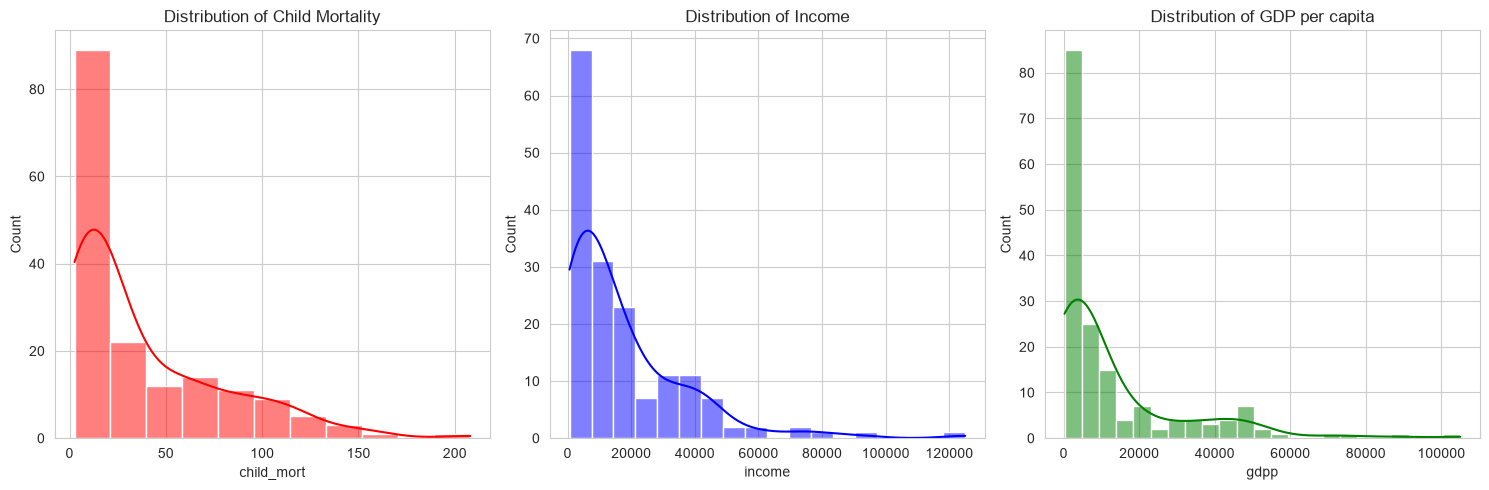

In [49]:
# Visualize the distribution of 'child_mort', 'income', and 'gdpp'
# Set up the figure size
plt.figure(figsize=(15, 5))

# Plot 1: Child Mortality
plt.subplot(1, 3, 1)
sns.histplot(df['child_mort'], kde=True, color='red')
plt.title('Distribution of Child Mortality')

# Plot 2: Income
plt.subplot(1, 3, 2)
sns.histplot(df['income'], kde=True, color='blue')
plt.title('Distribution of Income')

# Plot 3: GDP per capita
plt.subplot(1, 3, 3)
sns.histplot(df['gdpp'], kde=True, color='green')
plt.title('Distribution of GDP per capita')

plt.tight_layout()
plt.show()


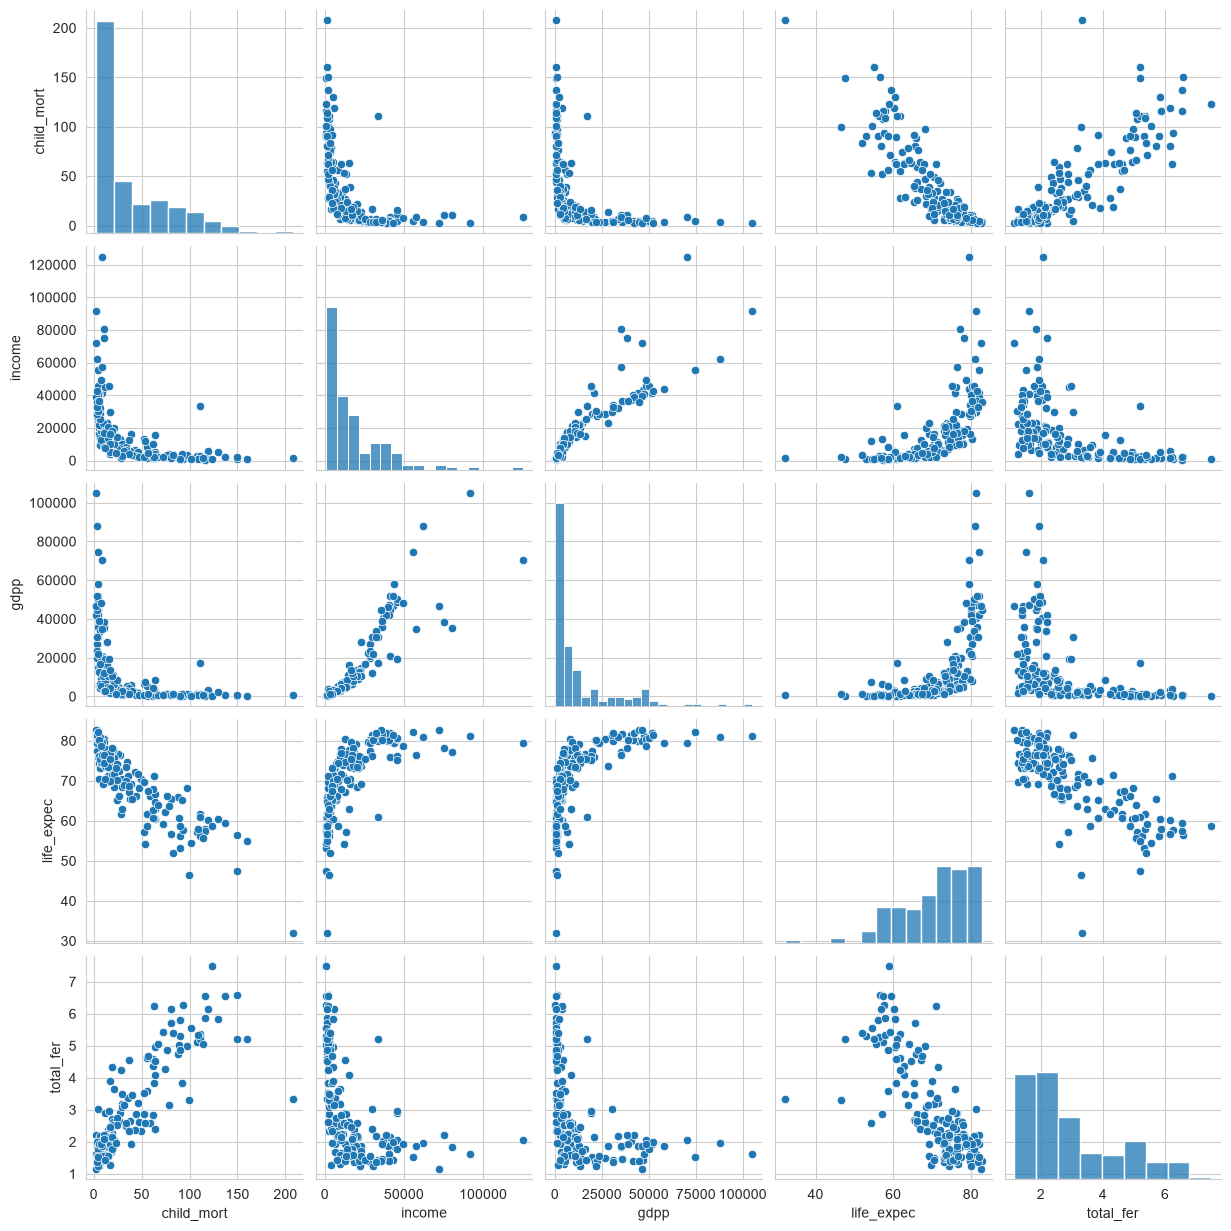

In [50]:
# Create pairplots to visualize relationships between features.
# We select a subset of features to keep the plot readable
selected_features = ['child_mort', 'income', 'gdpp', 'life_expec', 'total_fer']
sns.pairplot(df[selected_features])
plt.show()


### Task 2: Initial K-means Clustering

1. Drop the `'country'` column since it's not a numerical feature and we can't use it for clustering. Perform this step in a new DataFrame called `'df_cluster1'`.
2. Use StandardScaler to standardize the numerical features in 'df_cluster1', ensuring they have a mean of 0 and a standard deviation of 1, bringing all features onto a common scale.
3. Apply K-Means clustering to the standardized data in 'df_cluster1' with an initial number of clusters (e.g., 4).
4. Print the inertia and centroids obtained from the KMeans model to understand the clustering performance.
5. Add the cluster labels to the original DataFrame 'df'.
6. Create a pair plot to visualize the relationships between all relevant features, colored by cluster labels.

In [51]:
# Drop the 'country' column since it's not a numerical feature
df_cluster1 = df.drop('country', axis=1)


# Standardize the numerical features
scaler = StandardScaler()
# Fit and transform the data, then create a new DataFrame to keep column names
df_cluster1_scaled = pd.DataFrame(scaler.fit_transform(df_cluster1), columns=df_cluster1.columns)



#check few rows
df_cluster1_scaled.head()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,1.291532,-1.138280,0.279088,-0.082455,-0.808245,0.157336,-1.619092,1.902882,-0.679180
1,-0.538949,-0.479658,-0.097016,0.070837,-0.375369,-0.312347,0.647866,-0.859973,-0.485623
2,-0.272833,-0.099122,-0.966073,-0.641762,-0.220844,0.789274,0.670423,-0.038404,-0.465376
3,2.007808,0.775381,-1.448071,-0.165315,-0.585043,1.387054,-1.179234,2.128151,-0.516268
4,-0.695634,0.160668,-0.286894,0.497568,0.101732,-0.601749,0.704258,-0.541946,-0.041817


In [52]:
# Perform KMeans clustering withh n_clusters as 4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)


# Fit the KMeans model to the data (df_cluster)
# Note: Make sure to fit it to the SCALED data!
kmeans.fit(df_cluster1_scaled)


c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 9)","[[-0.

In [53]:
#Print the inertia and centroids

#Inertia
print("Inertia:", kmeans.inertia_)
print("\n")

#Centroids
print("Centroids:")
print(kmeans.cluster_centers_)


Inertia: 700.5205369722204


Centroids:
[[-8.22940855e-01  1.83308008e-01  8.29894098e-01 -2.61252058e-01
   1.39837771e+00 -4.99856230e-01  1.07433094e+00 -7.68250332e-01
   1.59543611e+00]
 [ 1.36021776e+00 -4.37533128e-01 -1.55984012e-01 -1.89203770e-01
  -6.86894080e-01  4.02110776e-01 -1.28217981e+00  1.36494385e+00
  -6.04242430e-01]
 [-4.12342560e-01 -1.28020671e-03 -2.25892629e-01  4.24525884e-02
  -2.32737556e-01 -1.63669262e-02  2.61216331e-01 -4.28844264e-01
  -3.52670040e-01]
 [-8.49003244e-01  4.93567278e+00 -8.16303241e-03  4.54805768e+00
   2.43954240e+00 -5.04206141e-01  1.22682431e+00 -1.03886271e+00
   2.44079735e+00]]


In [54]:
# Add the cluster labels to the original DataFrame 'df'.
# kmeans.labels_ contains the cluster assignment (0, 1, 2, or 3) for each row
df['cluster'] = kmeans.labels_

# Check the first few rows to ensure the column was added
df.head()


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,cluster
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,1
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,2
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,2
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,1
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,2


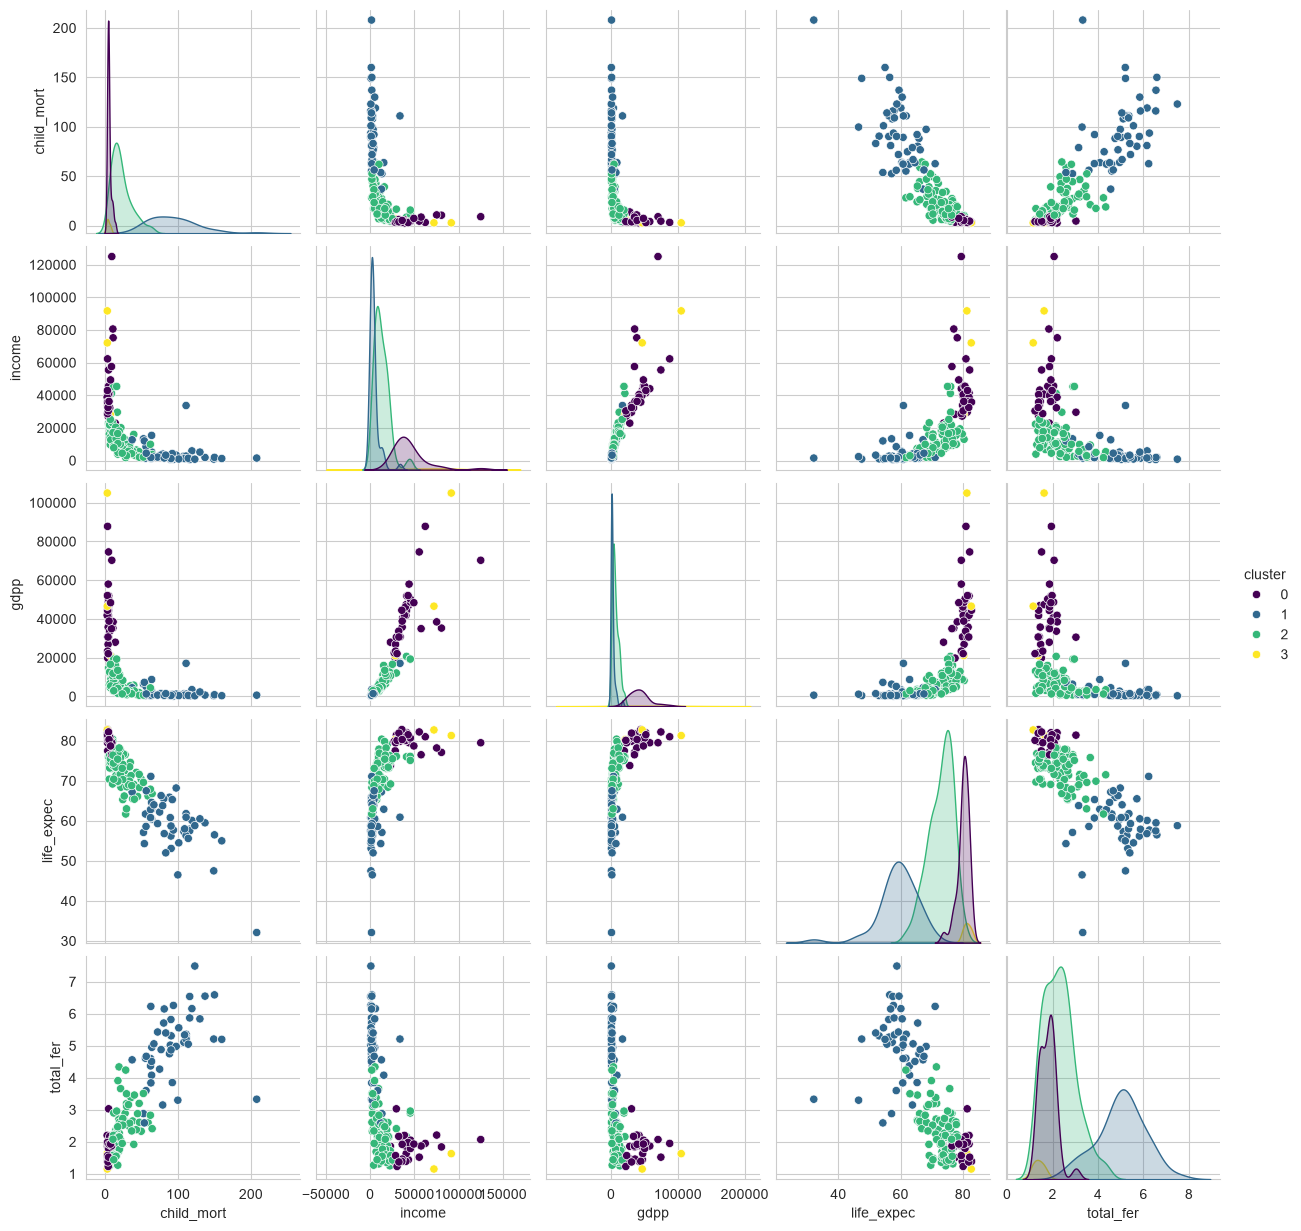

In [55]:
#Create a pair plot to visualize the relationships between all relevant features, colored by cluster labels.
# Because we have many features, we will use a subset for a readable pairplot
# We include 'cluster' as the hue to color the points by their assigned cluster
selected_features = ['child_mort', 'income', 'gdpp', 'life_expec', 'total_fer', 'cluster']
sns.pairplot(df[selected_features], hue='cluster', palette='viridis')
plt.show()


### Task3: Elbow Method for Determining Optimal Clusters

- Use the Elbow Method to determine the optimal number of clusters. Check clusters ranging from 1 to 20.
- Plot the Elbow Method graph to visualize the optimal number of clusters.
- Train the KMeans model using the number of clusters identified by the Elbow Method.

c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a m

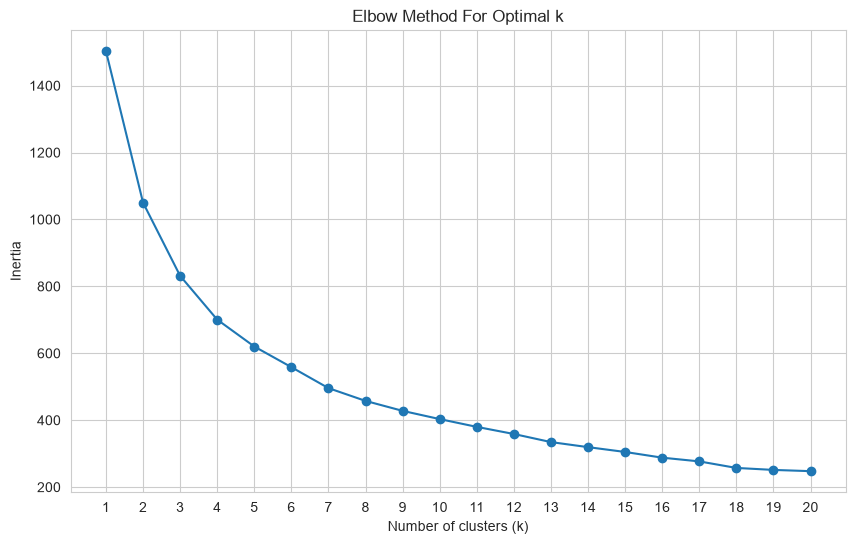

In [56]:
# Determine the optimal number of clusters using the Elbow Method
inertia = []
# Check clusters ranging from 1 to 20 (inclusive of 20)
K_range = range(1, 21) 

for k in K_range:
    # We use the scaled data (df_cluster1_scaled) created in Task 2
    kmeans_elbow = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_elbow.fit(df_cluster1_scaled)
    inertia.append(kmeans_elbow.inertia_)



# Plot the Elbow Method graph
plt.figure(figsize=(10, 6))
plt.plot(K_range, inertia, marker='o', linestyle='-')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.xticks(K_range) # Show all numbers 1-20 on the x-axis
plt.grid(True)
plt.show()

In [ ]:
# Train the KMeans model using the number of clusters identified by the Elbow Method.

# Perform KMeans clustering withh optimal n_clusters
# (Assuming the elbow indicates 7 clusters, change to 8 if your graph suggests otherwise)
optimal_k = 7
kmeans_optimal = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)

# Fit the KMeans model to the data (df_cluster)
kmeans_optimal.fit(df_cluster1_scaled)

#assigning the cluster values
# Add the new optimal labels back to the original DataFrame (overwriting the previous 'cluster' column)
df['cluster'] = kmeans_optimal.labels_

c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [58]:
#Print the inertia and centroids

#Inertia
print(f"Inertia for Optimal k={optimal_k}:", kmeans_optimal.inertia_)
print("\n")

#Centroids
print("Centroids (in scaled space):")
print(kmeans_optimal.cluster_centers_)

Inertia for Optimal k=7: 495.80794552153463


Centroids (in scaled space):
[[-6.76981113e-01  8.70515368e-01 -1.39329844e+00 -4.23563403e-01
   2.82888846e+00  5.29604041e-01  7.36213899e-01 -4.23790657e-01
   1.27610275e+00]
 [ 1.38751055e+00 -4.66594106e-01 -1.37846584e-01 -1.35937546e-01
  -7.12225760e-01  1.84001233e-01 -1.31560053e+00  1.37313929e+00
  -6.16446788e-01]
 [-2.47630455e-01 -3.90956765e-01 -5.16532882e-01 -5.36192809e-01
  -3.32312482e-01  2.58760491e-01  1.46604196e-01 -2.39821169e-01
  -4.12870410e-01]
 [-5.81007963e-01  4.22002351e-01  1.61672258e-01  6.32537810e-01
  -1.12070373e-01 -3.65898790e-01  3.89215117e-01 -6.34556820e-01
  -2.12023675e-01]
 [ 2.28138502e+00 -5.78451631e-01 -6.37438082e-01 -1.22178479e+00
  -6.24064774e-01  9.12971806e+00 -1.13412081e+00  1.91613337e+00
  -5.81936274e-01]
 [-8.44966266e-01 -1.38508536e-02  1.35024763e+00 -3.58055690e-01
   1.20292473e+00 -6.11719771e-01  1.16569211e+00 -7.53387851e-01
   1.77594870e+00]
 [-8.49003244e-01  

### Task 4: Hierarchical Clustering

1. Apply hierarchical clustering using Agglomerative Clustering with 6 clusters.
2. Use the following parameters: `metric='cosine', linkage='complete'`.
3. Assign cluster labels to the original DataFrame and print a sample of 10 rows to verify the cluster assignments.
4. Plot the dendrogram to visualize the hierarchical clustering process, using the first 50 data points to ensure clarity.
5. Create a pair plot to visualize the relationships between all relevant features, colored by cluster labels.

In [62]:
# Apply Agglomerative Clustering (6 clusters, metric='cosine', linkage='complete')
agg_clustering = AgglomerativeClustering(
    n_clusters=7, 
    metric='cosine', 
    linkage='complete'
)

# Fit the model to the scaled data and predict the clusters
# We use fit_predict to fit the model and get the labels in one step
hc_labels = agg_clustering.fit_predict(df_cluster1_scaled)

#Assign cluster labels to the original DataFrame and print a sample of 10 rows to verify the cluster assignments.
df['hc_cluster'] = hc_labels

# Print a sample of 10 rows to verify
print("Sample of 10 rows with Hierarchical Clustering labels:")
df.sample(10)

Sample of 10 rows with Hierarchical Clustering labels:


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,cluster,hc_cluster
11,Bahrain,8.6,69.5,4.97,50.9,41100,7.440,76.0,2.16,20700,3,6
137,South Africa,53.7,28.6,8.94,27.4,12000,6.350,54.3,2.59,7280,1,1
127,Samoa,18.9,29.2,6.47,53.1,5400,1.720,71.5,4.34,3450,2,1
97,Mali,137.0,22.8,4.98,35.1,1870,4.370,59.5,6.55,708,1,1
17,Benin,111.0,23.8,4.10,37.2,1820,0.885,61.8,5.36,758,1,1
15,Belgium,4.5,76.4,10.70,74.7,41100,1.880,80.0,1.86,44400,5,2
43,Czech Republic,3.4,66.0,7.88,62.9,28300,-1.430,77.5,1.51,19800,3,2
94,Malawi,90.5,22.8,6.59,34.9,1030,12.100,53.1,5.31,459,1,1
53,Finland,3.0,38.7,8.95,37.4,39800,0.351,80.0,1.87,46200,5,2
57,Georgia,16.5,35.0,10.10,52.8,6730,8.550,72.8,1.92,2960,3,2


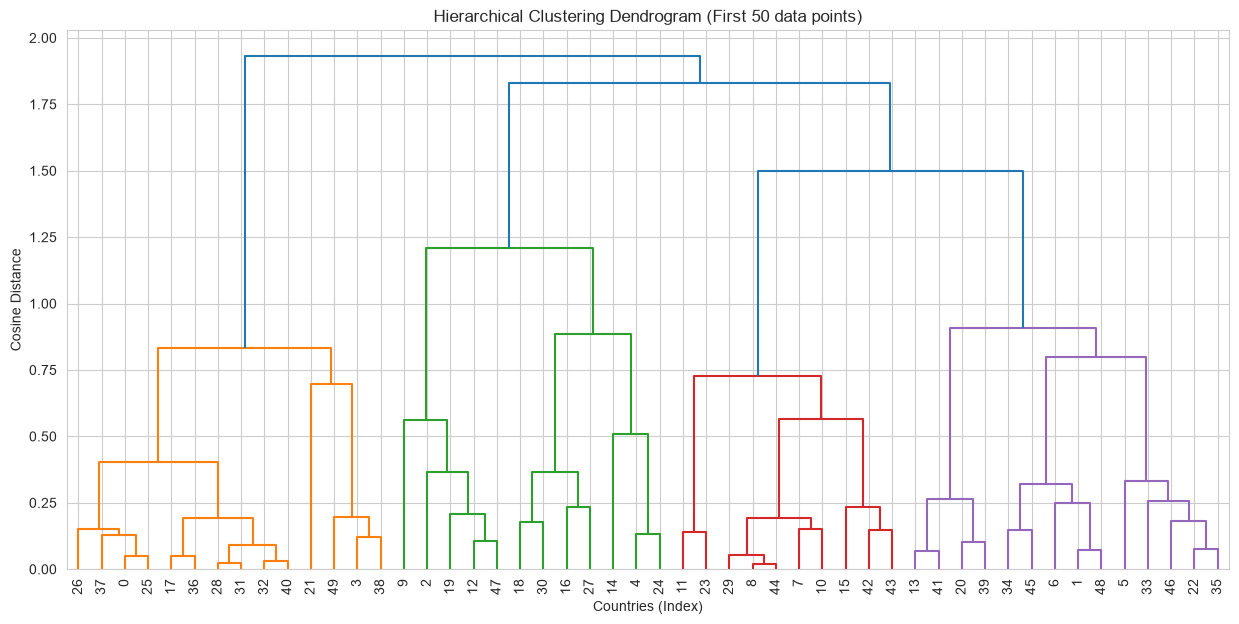

In [64]:
# Plot the dendrogram to visualize the hierarchical clustering process, using the first 50 data points



# Perform hierarchical/agglomerative clustering on subset
# We use the first 50 rows of the scaled data for clarity
subset_data = df_cluster1_scaled.iloc[:50]

# Plotting the dendrogram for subset
plt.figure(figsize=(15, 7))
plt.title('Hierarchical Clustering Dendrogram (First 50 data points)')
plt.xlabel('Countries (Index)')
plt.ylabel('Cosine Distance')

# Create the linkage matrix using the same metric and method
# (metric='cosine', method='complete')
linkage_matrix = sch.linkage(subset_data, metric='cosine', method='complete')

# Plot the dendrogram
sch.dendrogram(linkage_matrix, leaf_rotation=90, leaf_font_size=10)
plt.show()

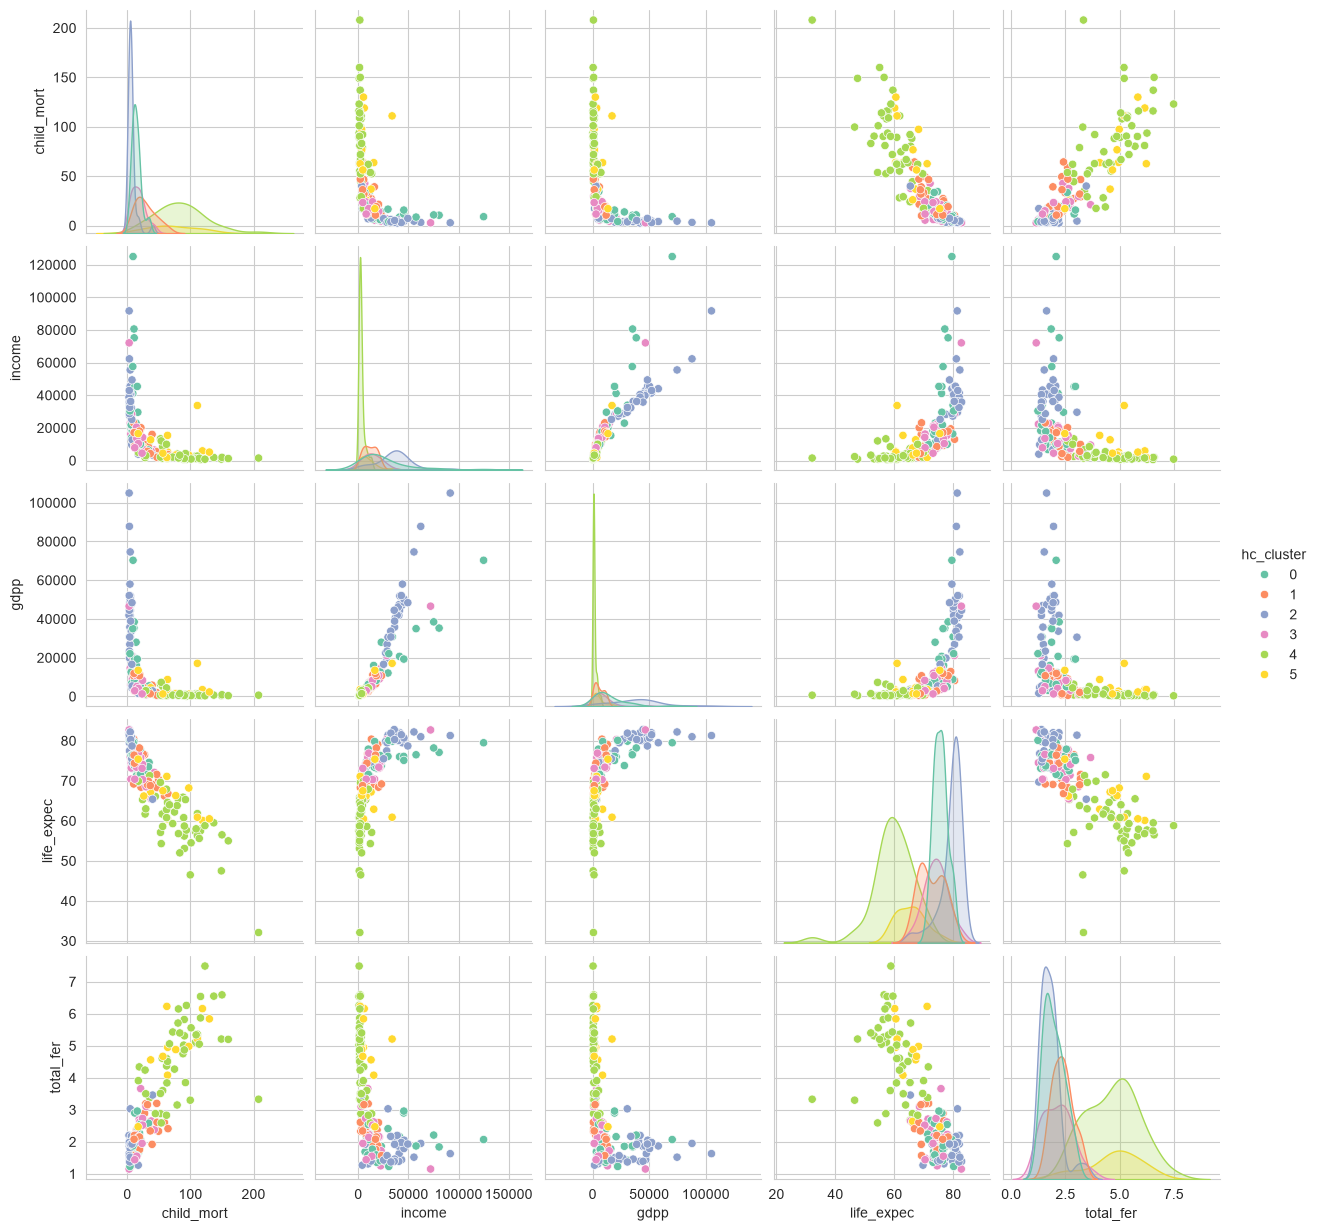

In [61]:
# Create a pair plot to visualize the relationships between all relevant features, colored by cluster labels.
# Select a subset of features for a readable plot
selected_features = ['child_mort', 'income', 'gdpp', 'life_expec', 'total_fer', 'hc_cluster']

# Create the pair plot, using 'hc_cluster' as the hue
sns.pairplot(df[selected_features], hue='hc_cluster', palette='Set2')
plt.show()
